# Evidencia científica nueva: observaciones y sensibilidad

Este notebook **lee** la evidencia nueva, sin sobrescribir notebooks 01–08 ni repetir NSGA-II. La comparación histórica conserva motor 1.1.0; sensibilidad y demos usan 1.1.1. Los referentes empíricos de observación son independientes del motor de RU. Ver `REAL_WORLD_VALIDATION.md` y matriz de rúbrica.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/project2/base.yaml').exists())
E=ROOT/'results/project2/scientific_validation'
S=ROOT/'results/project2/sensitivity_v111'
metadata=json.loads((E/'metadata.json').read_text(encoding='utf-8'))
display(pd.Series(metadata).to_frame('valor'))
display(pd.read_csv(E/'notebook_audit.csv'))


,valor
floral_rows,593
visitation_rows,1297
floral_traps,100
visitation_traps,101
floral_dates_contextualized,577
floral_start,2017-07-18
floral_end,2017-08-04
visitation_start,2017-07-18
visitation_end,2017-08-10
floral_complete_units,99


,notebook,sha256,cells,error_outputs,temporal_wording_requires_care,status
0,01_data_audit.ipynb,426eb563501f577fc909d5e189125d7679c9c73fa8d8f9...,28,0,False,reviewed; legacy outputs retained
1,02_spatial_model.ipynb,cc351a7d751190d611b980c5d2844cae4555b96215e433...,22,0,False,reviewed; legacy outputs retained
2,03_temporal_model.ipynb,b67f91ea0cb41b785737ef8adf5678dc8e7e0236dc91b5...,37,0,True,reviewed; legacy outputs retained
3,04_validation.ipynb,0a0d0a47caa977690d9f2ce3fdcc472d9e684c81271f2a...,26,0,True,reviewed; legacy outputs retained
4,05_baselines.ipynb,825b389b4f15100ed6b56cd633708463724836fd0e5db3...,6,0,False,reviewed; legacy outputs retained
5,06.2_ngsaii_implementation.ipynb,eaec8dbfad0a7d8e6ce2c77cc6963953dc1af35dd1c718...,21,0,False,reviewed; legacy outputs retained
6,06_optimization.ipynb,9bb1ec6bc87feb6e87b609e4c1d9315ff20919f731e4a0...,7,0,False,reviewed; legacy outputs retained
7,07_multivariate_analysis.ipynb,d5f42a2ebd11d734a75c56fdfa7a7c44fe5d8b315732c5...,7,0,False,reviewed; legacy outputs retained
8,08_final_results.ipynb,f470cc05bef2760aca6b170fef87fe6436b710dce06a4b...,5,0,False,reviewed; legacy outputs retained


## Evaluación por sitios fuera del ajuste

79 sitios de ajuste / 20 de evaluación por referente. Treinta bootstrap de sitios de ajuste y 2 000 bootstrap de sitios de evaluación para IC de error. MAE/RMSE tienen las mismas unidades observadas. No existe RU→flores ni viajes→individuos/minuto: estos errores no validan el motor de colmenas.


,dataset,method,metric,estimate,ci95_low,ci95_high,unit,train_sites,test_sites,train_units,test_units,train_bootstrap_replicates
0,flowers,global,MAE,10.227028,7.676632,12.969134,flores/m²,79,20,79,20,30
1,flowers,global,RMSE,11.788499,8.933878,14.797095,flores/m²,79,20,79,20,30
2,flowers,stratified,MAE,11.106329,8.462745,13.920433,flores/m²,79,20,79,20,30
3,flowers,stratified,RMSE,12.700899,9.893508,15.306625,flores/m²,79,20,79,20,30
4,activity,global,MAE,0.925099,0.697287,1.178132,conteos registrados/minuto de sesión candidata,79,20,169,47,30
5,activity,global,RMSE,1.126583,0.842474,1.432922,conteos registrados/minuto de sesión candidata,79,20,169,47,30
6,activity,stratified,MAE,0.842494,0.626203,1.068460,conteos registrados/minuto de sesión candidata,79,20,169,47,30
7,activity,stratified,RMSE,1.055442,0.808794,1.300252,conteos registrados/minuto de sesión candidata,79,20,169,47,30


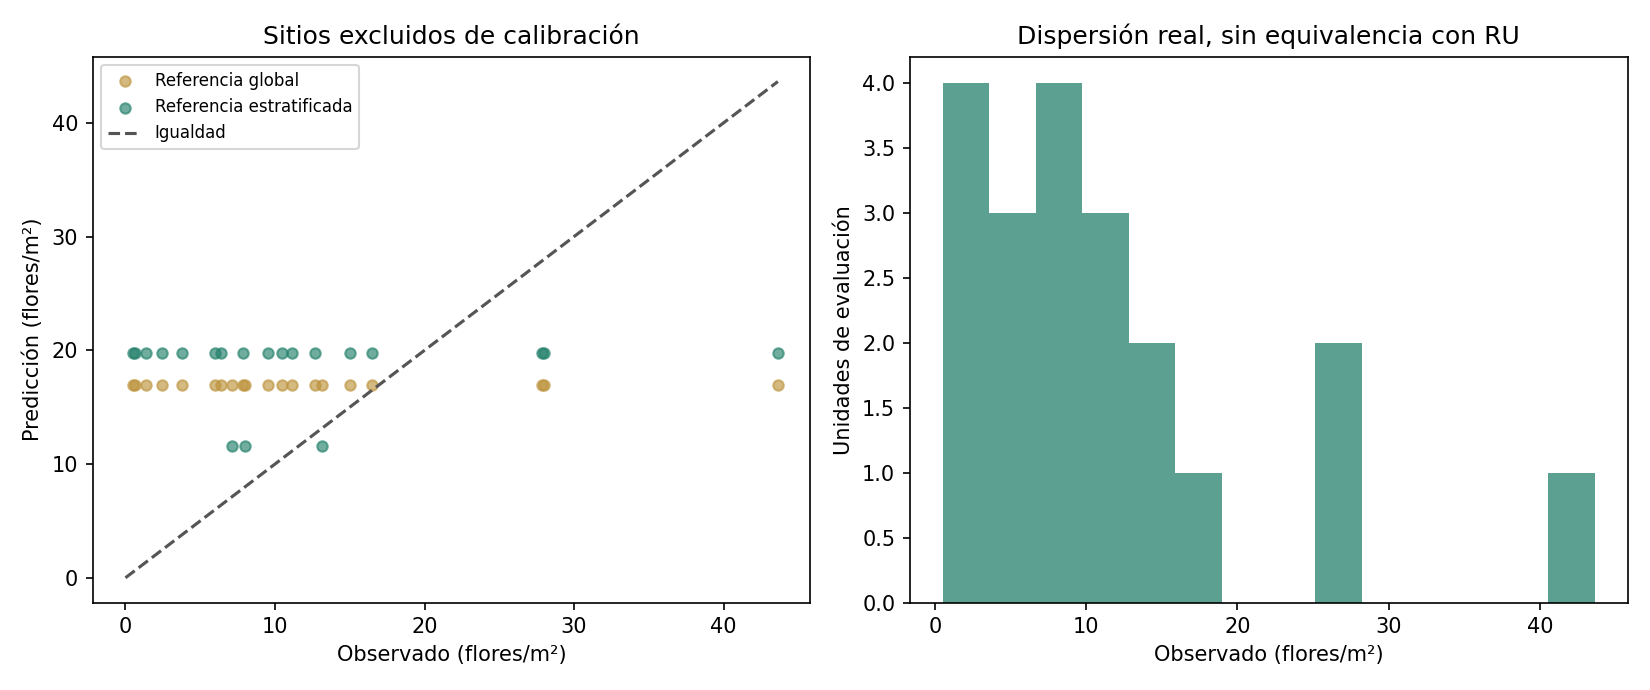

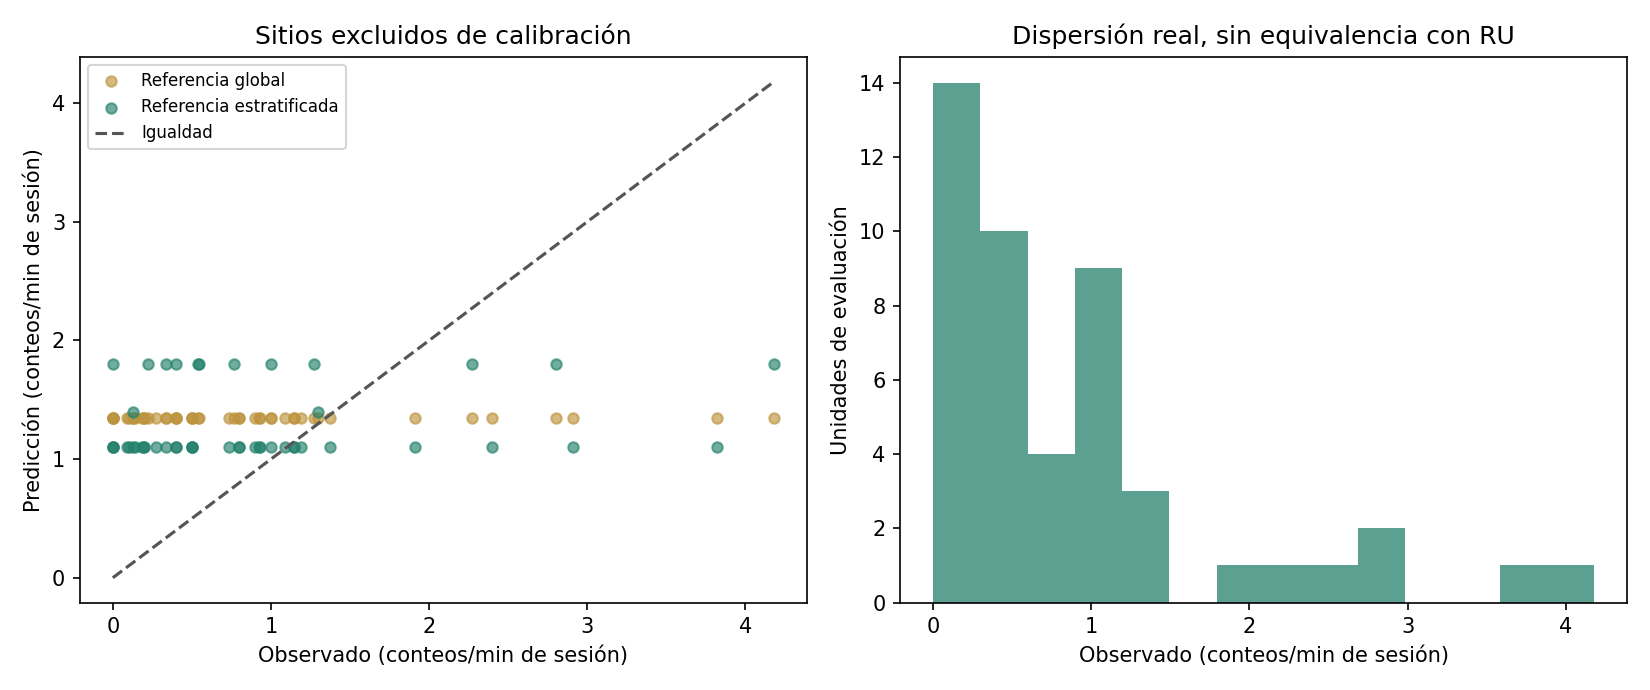

In [2]:
display(pd.read_csv(E/'empirical_errors.csv'))
for name in ['flowers','activity']:
    split=pd.read_csv(E/f'{name}_split.csv')
    train=set(split.loc[split.split.eq('calibration'),'trap_number'])
    test=set(split.loc[split.split.eq('evaluation'),'trap_number'])
    assert not train & test
    assert pd.read_csv(E/f'{name}_replicates.csv').replication_id.nunique()==30
    display(Image(filename=str(E/f'{name}_validation.png')))


## Diferencias absolutas y porcentuales históricas

Son diferencias pareadas sobre 70 seeds; RANDOM se agrega primero por seed. Porcentajes firmados respecto de media base fija; ausentes si base cero. No son una prueba confirmatoria ni incertidumbre entre optimizer seeds.


In [3]:
changes=pd.read_csv(E/'archived_changes.csv')
display(changes.loc[changes.metric.eq('total_resource_obtained')])


,Index,contrast,metric,difference,ci95_low,ci95_high,n_pairs,undefined_pairs,bootstrap_seed,baseline_mean,percent_change,percentage_ci_low_conditional_on_baseline_mean,percentage_ci_high_conditional_on_baseline_mean,note
0,0,GREEDY-RANDOM,total_resource_obtained,192.713657,188.610956,196.647694,70,0,2017,721.661992,26.704144,26.135637,27.249280,"sign is change, not universal improvement; per..."
9,9,NSGA2-RANDOM,total_resource_obtained,206.124715,201.769722,210.503982,70,0,2017,721.661992,28.562501,27.959034,29.169332,"sign is change, not universal improvement; per..."
18,18,NSGA2-GREEDY,total_resource_obtained,13.411058,9.252688,17.379619,70,0,2017,914.375650,1.466690,1.011913,1.900709,"sign is change, not universal improvement; per..."


## Sensibilidad de un factor por vez

14 condiciones, 1 200 simulaciones, 30 seeds comunes por método/condición. No hay NSGA-II para K distinto de cinco: no se inventa un frente. Se reevalúan ubicaciones congeladas, no se reoptimiza. El cambio de K también cambia oportunidades totales. Presión casi cero limita la señal del objetivo competencia.


,condition,method,metric,mean,std,n,estimate,ci_lower,ci_upper,confidence,n_boot,seed
0,K3,GREEDY,total_resource_obtained,565.598987,21.888019,30,565.598987,557.859736,573.014957,0.95,2000,17
1,K3,GREEDY,min_resource_per_hive,167.590270,8.189583,30,167.590270,164.684330,170.500936,0.95,2000,17
2,K3,GREEDY,mean_distance_m,1297.674121,30.045261,30,1297.674121,1287.208706,1308.084027,0.95,2000,17
3,K3,GREEDY,competition_pressure,0.000206,0.000534,30,0.000206,0.000050,0.000411,0.95,2000,17
4,K3,GREEDY,hive_balance_jain,0.990259,0.006374,30,0.990259,0.988010,0.992407,0.95,2000,17
...,...,...,...,...,...,...,...,...,...,...,...,...
195,resource_low,RANDOM,total_resource_obtained,462.223337,10.278486,30,462.223337,458.621726,465.876252,0.95,2000,17
196,resource_low,RANDOM,min_resource_per_hive,50.632241,2.990954,30,50.632241,49.623798,51.680824,0.95,2000,17
197,resource_low,RANDOM,mean_distance_m,1620.995598,16.564163,30,1620.995598,1615.213669,1626.642084,0.95,2000,17
198,resource_low,RANDOM,competition_pressure,0.000066,0.000250,30,0.000066,0.000000,0.000164,0.95,2000,17


,condition,method,metric,n_pairs,estimate,ci_lower,ci_upper,confidence,n,n_boot,seed
0,K3,GREEDY,total_resource_obtained,30,-354.234162,-361.563038,-346.559705,0.95,30,2000,17
1,K3,GREEDY,min_resource_per_hive,30,9.942863,6.178638,14.259128,0.95,30,2000,17
2,K3,GREEDY,mean_distance_m,30,-19.310327,-28.161763,-10.853298,0.95,30,2000,17
3,K3,GREEDY,competition_pressure,30,-0.000106,-0.000373,0.000135,0.95,30,2000,17
4,K3,GREEDY,hive_balance_jain,30,0.002584,0.000464,0.004831,0.95,30,2000,17
...,...,...,...,...,...,...,...,...,...,...,...
195,resource_low,RANDOM,total_resource_obtained,30,-263.524823,-269.665825,-257.488898,0.95,30,2000,17
196,resource_low,RANDOM,min_resource_per_hive,30,-48.439278,-50.014582,-46.978730,0.95,30,2000,17
197,resource_low,RANDOM,mean_distance_m,30,7.760176,-0.556783,15.812733,0.95,30,2000,17
198,resource_low,RANDOM,competition_pressure,30,-0.000185,-0.000342,-0.000027,0.95,30,2000,17


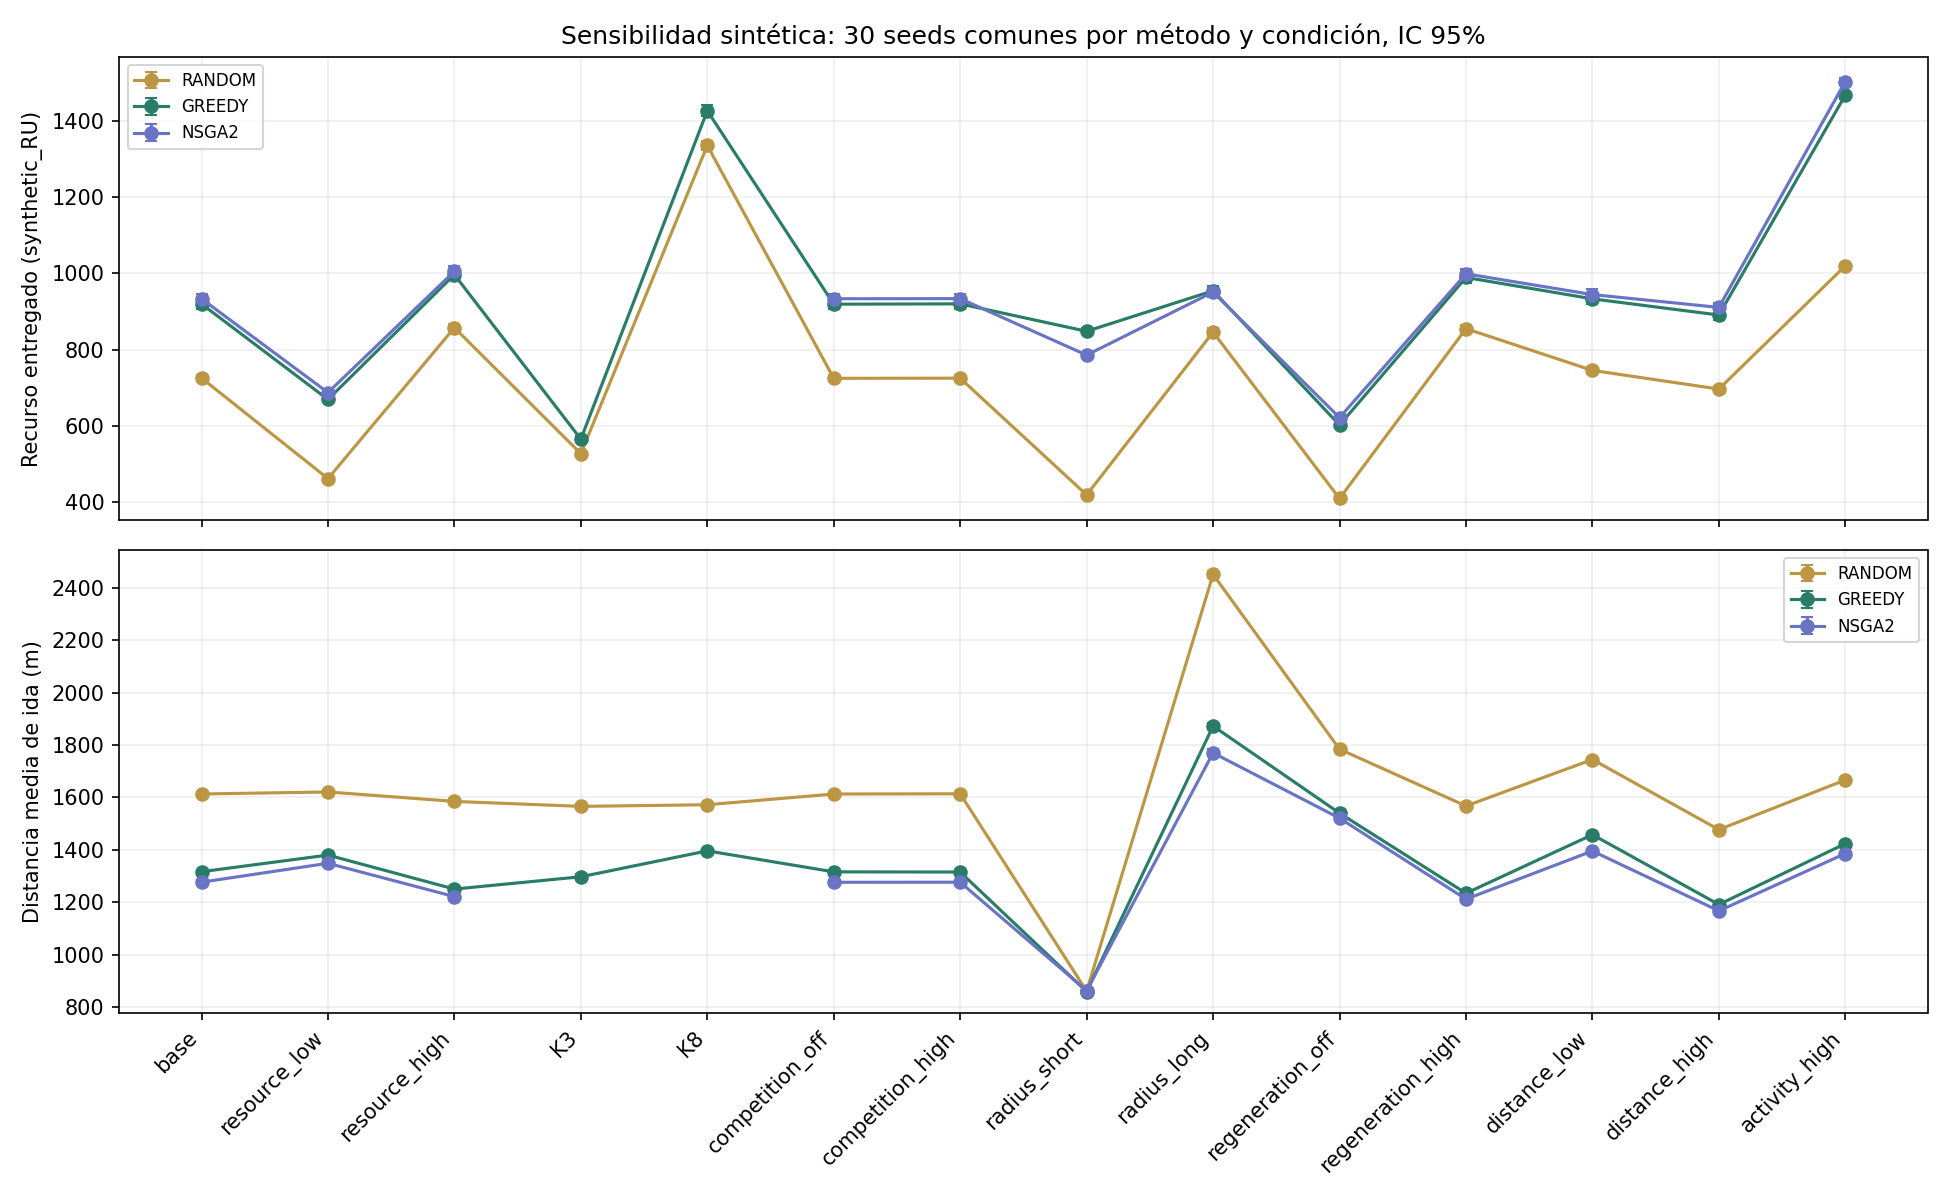

In [4]:
runs=pd.read_csv(S/'replicates.csv')
assert len(runs)==1200
assert runs.engine_version.eq('project2-synthetic-1.1.1').all()
assert runs.groupby(['experiment_condition','method']).replication_id.nunique().eq(30).all()
summary=pd.read_csv(S/'summary.csv')
display(summary)
display(pd.read_csv(S/'paired_vs_base.csv'))
display(Image(filename=str(S/'sensitivity.png')))


## Conclusiones y pendientes

La estratificación mensual empeora el error floral fuera de muestra. La alternativa por temperatura reduce el error de actividad en este split, sin demostrar causalidad ni validar viajes. Recursos, radio y oportunidades cambian el desempeño sintético y pueden cambiar rankings. La competencia simultánea del modelo actual es rara.

Siguen pendientes correspondencia espacial, detectabilidad, población/colonia y parámetros biológicos; múltiples optimizer seeds, política de colocalización e interacciones; informe PDF, diapositivas y defensa humana. El criterio de comparación real no se considera resuelto para el motor de colmenas.
